# H2 supporting study: standardisation

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.lines import Line2D

from fsr.standardisation.results import (
    CONTROL,
    UNTRAINED,
    WINNER,
    agreement_table,
    available,
    contrast_table,
    format_table,
    guardrail_table,
    hard_subset,
    inconsistency_table,
    levels_table,
    oracle_table,
)
from fsr.standardisation.store import load_tensor

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "grid.linewidth": 0.6,
        "grid.alpha": 0.45,
        "axes.edgecolor": "0.3",
        "axes.linewidth": 0.9,
    }
)

BAR_FILL = sns.color_palette("pastel")[0]
BAR_EDGE = sns.color_palette("muted")[0]
MUTED_FILL = "0.88"
MUTED_EDGE = "0.6"
RULE = "0.35"
ERROR = "0.45"
JOIN = "0.8"
DIVERGING = "RdBu_r"

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
DATA_ROOT = ROOT / "data" / "nq"
FIG_DIR = ROOT / "notebooks" / "h2" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

LEAD = "share of hard queries the gold leads"


def save(fig, name):
    """Write the figure as a vector PDF for the thesis and a PNG to read."""
    fig.tight_layout()
    for suffix in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{suffix}", bbox_inches="tight")


def fills(flags):
    """Return the fill and edge colour of each mark, by whether it resolved."""
    return (
        [BAR_FILL if f else MUTED_FILL for f in flags],
        [BAR_EDGE if f else MUTED_EDGE for f in flags],
    )


def key(labels):
    """Return the legend of the three conditions, in fixed colours and shapes."""
    return [
        Line2D(
            [],
            [],
            ls="",
            marker=shape,
            ms=size,
            mew=0.9,
            mfc=fill,
            mec=edge,
            label=text,
        )
        for shape, size, fill, edge, text in zip(
            ["o", "o", "D"],
            [8, 8, 7],
            [MUTED_FILL, "white", BAR_FILL],
            [MUTED_EDGE, BAR_EDGE, BAR_EDGE],
            labels,
            strict=True,
        )
    ]


SLUGS = available(DATA_ROOT)
HARD = hard_subset(DATA_ROOT, SLUGS)
levels = levels_table(DATA_ROOT, SLUGS, subset=HARD)
ORDER = levels.xs(UNTRAINED, level="condition")["standardised_mean"].sort_values().index
Y = np.arange(len(ORDER))

n_hard = len(next(iter(HARD.values())))
n_total = load_tensor(DATA_ROOT, "test", SLUGS[0], "base").n_queries
print(f"{len(SLUGS)} models, three conditions each")
print(f"hard subset: {n_hard} of {n_total} queries")

6 models, three conditions each
hard subset: 153 of 767 queries


## Accuracy on hard queries

In [2]:
levels.round(4)

standardised_mean  standardised_best   mixed
model      condition                                               
MiniLM-L6  untrained              0.3059             0.3203  0.3142
           rank only              0.5516             0.5817  0.5586
           invariance             0.5412             0.5229  0.5390
MiniLM-L12 untrained              0.3595             0.4052  0.3619
           rank only              0.6379             0.6601  0.6414
           invariance             0.6157             0.6275  0.6174
bge-base   untrained              0.4222             0.4248  0.4201
           rank only              0.6484             0.6601  0.6441
           invariance             0.6706             0.6863  0.6676
bge-v2-m3  untrained              0.6810             0.7059  0.6666
           rank only              0.7333             0.7778  0.7334
           invariance             0.7778             0.7974  0.7757
mxbai-v1   untrained              0.4993             0.5229  0.4878
           rank only              0.7556             0.7712  0.7416
           invariance             0.7529             0.7778  0.7448
jina-v2    untrained              0.5425             0.5817  0.5355
           rank only              0.7190             0.7451  0.7171
           invariance             0.7320             0.7451  0.7329

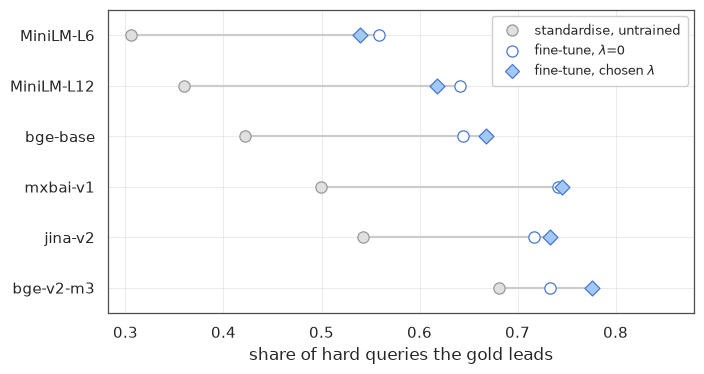

In [3]:
standardised = levels.xs(UNTRAINED, level="condition").loc[ORDER, "standardised_mean"]
control = levels.xs(CONTROL, level="condition").loc[ORDER, "mixed"]
winner = levels.xs(WINNER, level="condition").loc[ORDER, "mixed"]

fig, ax = plt.subplots(figsize=(7.2, 3.9))
ax.hlines(Y, standardised, np.maximum(control, winner), color=JOIN, lw=1.6, zorder=1)
ax.scatter(
    standardised,
    Y,
    s=66,
    marker="o",
    color=MUTED_FILL,
    edgecolor=MUTED_EDGE,
    linewidth=0.9,
    zorder=3,
)
ax.scatter(
    control,
    Y,
    s=66,
    marker="o",
    color="white",
    edgecolor=BAR_EDGE,
    linewidth=0.9,
    zorder=3,
)
ax.scatter(
    winner,
    Y,
    s=58,
    marker="D",
    color=BAR_FILL,
    edgecolor=BAR_EDGE,
    linewidth=0.9,
    zorder=4,
)

ax.set_yticks(Y)
ax.set_yticklabels(ORDER)
ax.set_ylim(len(ORDER) - 0.5, -0.5)
ax.set_xlim(None, 0.88)
ax.set_xlabel(LEAD)
ax.legend(
    handles=key(
        [
            "standardise, untrained",
            "fine-tune, $\\lambda$=0",
            "fine-tune, chosen $\\lambda$",
        ]
    ),
    loc="upper right",
    fontsize=9,
    frameon=True,
    facecolor="white",
    edgecolor="0.8",
    framealpha=0.95,
    borderpad=0.6,
).set_zorder(5)
save(fig, "standardisation_levels")

## Paired contrasts

In [4]:
against_standardisation = contrast_table(
    DATA_ROOT, SLUGS, (WINNER, "mixed"), (UNTRAINED, "standardised_mean"), subset=HARD
)
invariance_term = contrast_table(
    DATA_ROOT, SLUGS, (WINNER, "mixed"), (CONTROL, "mixed"), subset=HARD
)
adaptation_only = contrast_table(
    DATA_ROOT, SLUGS, (CONTROL, "mixed"), (UNTRAINED, "standardised_mean"), subset=HARD
)
against_standardisation.round(4)

,diff,ci_lo,ci_hi,p,p_floor,holm_p,resolved
model,,,,,,,
MiniLM-L6,0.2331,0.1620,0.3058,0.0000,0.0,0.0003,True
MiniLM-L12,0.2579,0.1879,0.3297,0.0000,0.0,0.0003,True
bge-base,0.2454,0.1769,0.3139,0.0000,0.0,0.0003,True
bge-v2-m3,0.0947,0.0271,0.1622,0.0066,0.0,0.0066,True
mxbai-v1,0.2455,0.1677,0.3218,0.0000,0.0,0.0003,True
jina-v2,0.1904,0.1163,0.2627,0.0000,0.0,0.0003,True


lambda=0 over standardise, untrained       resolved on 5/6
chosen lambda over standardise, untrained  resolved on 6/6
chosen lambda over lambda=0                resolved on 0/6


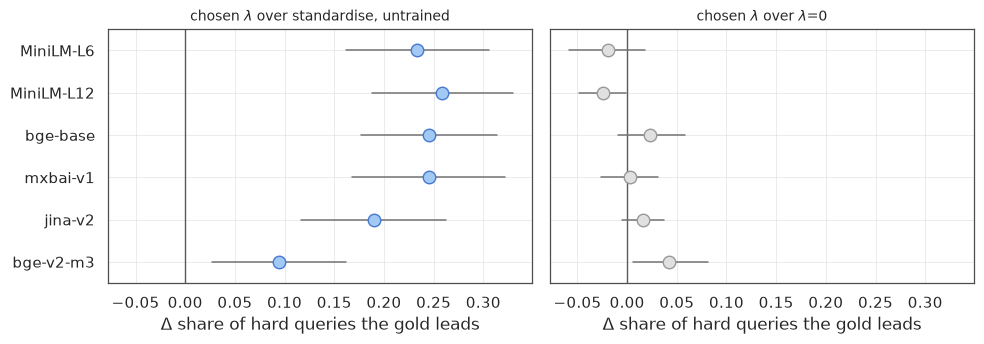

In [5]:
panels = [
    (against_standardisation, "chosen $\\lambda$ over standardise, untrained"),
    (invariance_term, "chosen $\\lambda$ over $\\lambda$=0"),
]

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True, sharex=True)
for ax, (table, title) in zip(axs, panels, strict=True):
    rows = table.loc[ORDER]
    fill, edge = fills(rows["resolved"])
    for pos, value, low, high, f, e in zip(
        Y, rows["diff"], rows["ci_lo"], rows["ci_hi"], fill, edge, strict=True
    ):
        ax.plot([low, high], [pos, pos], color=ERROR, lw=1.1, zorder=2)
        ax.plot([value], [pos], marker="o", ms=9, mfc=f, mec=e, mew=1.0, zorder=3)
    ax.axvline(0, color=RULE, lw=1, zorder=1)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("$\\Delta$ " + LEAD)

axs[0].set_yticks(Y)
axs[0].set_yticklabels(ORDER)
axs[0].set_ylim(len(ORDER) - 0.5, -0.5)
save(fig, "standardisation_contrast")

for name, table in (
    ("lambda=0 over standardise, untrained", adaptation_only),
    ("chosen lambda over standardise, untrained", against_standardisation),
    ("chosen lambda over lambda=0", invariance_term),
):
    print(f"{name:<42} resolved on {int(table['resolved'].sum())}/{len(table)}")

## Per format

best format: MiniLM-L6 inline_kv, MiniLM-L12 inline_kv, bge-base inline_kv, mxbai-v1 toml, jina-v2 markdown, bge-v2-m3 inline_kv


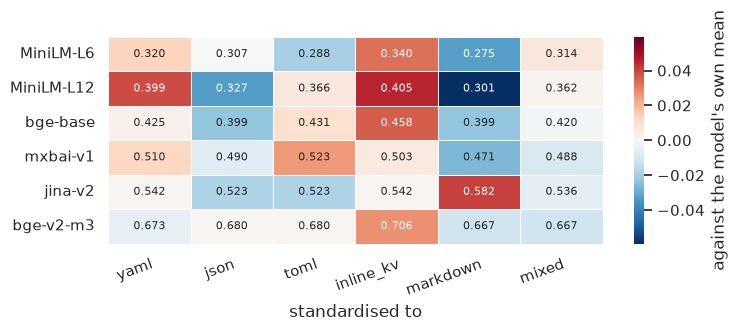

In [6]:
grid = format_table(DATA_ROOT, SLUGS, subset=HARD).loc[ORDER]
centred = grid.sub(grid.mean(axis=1), axis=0)
limit = np.abs(centred.to_numpy()).max()

fig, ax = plt.subplots(figsize=(7.6, 3.2))
sns.heatmap(
    centred,
    annot=grid.map(lambda v: f"{v:.3f}"),
    fmt="",
    cmap=DIVERGING,
    center=0,
    vmin=-limit,
    vmax=limit,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"fontsize": 8},
    cbar_kws={"label": "against the model's own mean"},
    ax=ax,
)
ax.set_xlabel("standardised to")
ax.set_ylabel("")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right", rotation_mode="anchor")
save(fig, "standardisation_formats")

best = grid[grid.columns[:-1]].idxmax(axis=1)
print("best format: " + ", ".join(f"{m} {f}" for m, f in best.items()))

## Agreement across formats

In [7]:
agreement = agreement_table(DATA_ROOT, SLUGS, subset=HARD).loc[ORDER]
agreement[
    [
        "disagree_untrained",
        "disagree_rank only",
        "disagree_invariance",
        "diff",
        "ci_lo",
        "ci_hi",
        "holm_p",
        "resolved",
    ]
].round(4)

,disagree_untrained,disagree_rank only,disagree_invariance,diff,ci_lo,ci_hi,holm_p,resolved
model,,,,,,,,
MiniLM-L6,0.2941,0.3595,0.3007,-0.0588,-0.1307,0.0196,0.5133,False
MiniLM-L12,0.3725,0.2353,0.2288,-0.0065,-0.0654,0.0523,1.0000,False
bge-base,0.3791,0.2353,0.1176,-0.1176,-0.1961,-0.0392,0.0287,True
mxbai-v1,0.1307,0.0654,0.0719,0.0065,-0.0327,0.0523,1.0000,False
jina-v2,0.2157,0.2614,0.1569,-0.1046,-0.1699,-0.0458,0.0159,True
bge-v2-m3,0.1895,0.1699,0.0654,-0.1046,-0.1765,-0.0327,0.0287,True


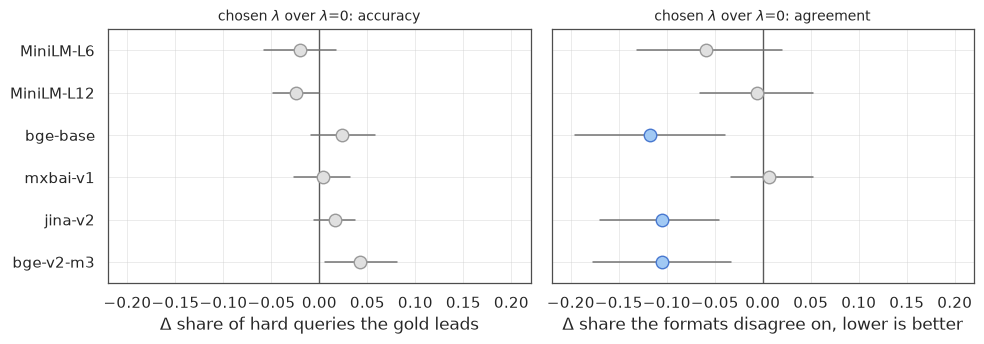

In [8]:
outcomes = [
    (invariance_term, "accuracy", "$\\Delta$ " + LEAD),
    (
        agreement,
        "agreement",
        "$\\Delta$ share the formats disagree on, lower is better",
    ),
]

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (table, title, label) in zip(axs, outcomes, strict=True):
    rows = table.loc[ORDER]
    fill, edge = fills(rows["resolved"])
    for pos, value, low, high, f, e in zip(
        Y, rows["diff"], rows["ci_lo"], rows["ci_hi"], fill, edge, strict=True
    ):
        ax.plot([low, high], [pos, pos], color=ERROR, lw=1.1, zorder=2)
        ax.plot([value], [pos], marker="o", ms=9, mfc=f, mec=e, mew=1.0, zorder=3)
    ax.axvline(0, color=RULE, lw=1, zorder=1)
    ax.set_title(f"chosen $\\lambda$ over $\\lambda$=0: {title}", fontsize=10)
    ax.set_xlabel(label)
    ax.set_xlim(-0.22, 0.22)

axs[0].set_yticks(Y)
axs[0].set_yticklabels(ORDER)
axs[0].set_ylim(len(ORDER) - 0.5, -0.5)
save(fig, "standardisation_stability")

## Robustness checks

In [9]:
inconsistency_table(DATA_ROOT, SLUGS, subset=HARD)[
    ["n_answerable", "n_inconsistent", "inconsistency_pct"]
].round(2)

n_answerable  n_inconsistent  inconsistency_pct
model      condition                                                  
MiniLM-L6  untrained             73              45              61.64
           rank only            114              55              48.25
           invariance           105              46              43.81
MiniLM-L12 untrained             84              57              67.86
           rank only            113              36              31.86
           invariance           111              35              31.53
bge-base   untrained             91              58              63.74
           rank only            114              36              31.58
           invariance           112              18              16.07
bge-v2-m3  untrained            116              29              25.00
           rank only            124              26              20.97
           invariance           124              10               8.06
mxbai-v1   untrained             87              20              22.99
           rank only            121              10               8.26
           invariance           121              11               9.09
jina-v2    untrained            101              33              32.67
           rank only            126              40              31.75
           invariance           122              24              19.67

In [10]:
oracle_table(DATA_ROOT, SLUGS, subset=HARD).round(4)

floor  best_format  ceiling  headroom  n_queries
model      condition                                                    
MiniLM-L6  untrained   0.1830       0.3399   0.4771    0.1373        153
           rank only   0.3856       0.5817   0.7451    0.1634        153
           invariance  0.3856       0.5882   0.6863    0.0980        153
MiniLM-L12 untrained   0.1765       0.4052   0.5490    0.1438        153
           rank only   0.5033       0.6601   0.7386    0.0784        153
           invariance  0.4967       0.6275   0.7255    0.0980        153
bge-base   untrained   0.2157       0.4575   0.5948    0.1373        153
           rank only   0.5098       0.6601   0.7451    0.0850        153
           invariance  0.6144       0.6863   0.7320    0.0458        153
bge-v2-m3  untrained   0.5686       0.7059   0.7582    0.0523        153
           rank only   0.6405       0.7778   0.8105    0.0327        153
           invariance  0.7451       0.7974   0.8105    0.0131        153
mxbai-v1   untrained   0.4379       0.5229   0.5686    0.0458        153
           rank only   0.7255       0.7712   0.7908    0.0196        153
           invariance  0.7190       0.7778   0.7908    0.0131        153
jina-v2    untrained   0.4444       0.5817   0.6601    0.0784        153
           rank only   0.5621       0.7451   0.8235    0.0784        153
           invariance  0.6405       0.7451   0.7974    0.0523        153

In [11]:
guardrail_table(DATA_ROOT, SLUGS)[
    ["uniform_best_mrr", "mixed_top1", "delta", "ni_margin", "kept"]
].round(4)

uniform_best_mrr  mixed_top1   delta  ni_margin   kept
model      condition                                                         
MiniLM-L6  untrained             0.9005      0.8172 -0.0833       0.03  False
           rank only             0.9426      0.8926 -0.0500       0.03  False
           invariance            0.9396      0.8891 -0.0505       0.03  False
MiniLM-L12 untrained             0.9166      0.8441 -0.0725       0.03  False
           rank only             0.9557      0.9168 -0.0389       0.03  False
           invariance            0.9532      0.9125 -0.0407       0.03  False
bge-base   untrained             0.9166      0.8394 -0.0772       0.03  False
           rank only             0.9557      0.9172 -0.0385       0.03  False
           invariance            0.9603      0.9266 -0.0337       0.03  False
bge-v2-m3  untrained             0.9665      0.9304 -0.0361       0.03  False
           rank only             0.9695      0.9385 -0.0310       0.03  False
           invariance            0.9742      0.9493 -0.0249       0.03   True
mxbai-v1   untrained             0.9366      0.8823 -0.0544       0.03  False
           rank only             0.9682      0.9414 -0.0268       0.03   True
           invariance            0.9686      0.9413 -0.0273       0.03   True
jina-v2    untrained             0.9515      0.9066 -0.0449       0.03  False
           rank only             0.9679      0.9379 -0.0300       0.03   True
           invariance            0.9683      0.9415 -0.0269       0.03   True